# Project AGAP: Household Flood Risk Classification for Santa Cruz, Laguna

**CSST 102 – Final Machine Learning Project Notebook (Weeks 1 to 7)**
CS 3-B · Group 9

*Project AGAP: AI-Based Flood Vulnerability Assessment and Evacuation Prioritization System for Santa Cruz, Laguna*

| Part | Week | What it covers |
|---|---|---|
| 1 | Week 1 | Problem formulation, test cell, loading the dataset |
| 2 | Week 2 | Data inspection, target and features, cleaning, encoding and split plan |
| 3 | Week 3 | Preprocessing, grouped train/test split, baseline model, saved predictions |
| 4 | Week 4 | Evaluation of the baseline with confidence intervals, interpretation, comparison with Random Forest and Logistic Regression |
| 5 | Week 5 | Feature engineering and tuning on a validation split, overfitting check, error analysis, bias check, final model |
| 6 | Week 6 | Notebook map, run instructions, reproducibility checks, references |
| 7 | Week 7 | Final results, demonstration of the working model, conclusions |

**How to run in Google Colab**

1. Choose **Runtime → Run all**.
2. When the data cell (1.2) asks for a file, upload `AGAP_Colab_Data.zip`. Or put the zip in Google Drive and set `USE_GOOGLE_DRIVE = True`.
3. A full run takes about 20–30 minutes on a free Colab runtime. Most of that time goes to model training in Parts 3 to 5. The flags `RUN_CV` (3.6, 5.6) and `RUN_IMPORTANCE` (3.7) can be set to `False` to save time.
4. The last cell packs every output into `AGAP_outputs.zip` and downloads it.

Every random step uses a fixed seed, so a second run gives the same numbers.

---
# Part 1 · Week 1: Machine Learning Problem Formulation

### Problem
Flood risk in Santa Cruz, Laguna differs from one household to the next. Two houses in the same barangay can face very
different danger depending on how close they are to a waterway, how high the ground is, what the house is made of, and
whether children, elderly members or persons with disability live there. Official hazard maps show where floodwater goes,
but they do not describe the people who live there.

### Guiding question
*Given a household's location, terrain, the official flood hazard at its site, the rainfall during an event and its
household profile, can a model classify the household's flood risk as **Low**, **Medium** or **High**?*

### Objectives
1. Build a household-level dataset from official flood hazard maps, terrain layers and historical rainfall.
2. Train and evaluate a classifier that assigns a risk level to each household for a given rain event.
3. Use the trained model in a map-based tool that supports evacuation prioritization.

### ML task
Supervised **multi-class classification**. One record is one household during one rainfall event, and the output is
`RiskLevel` (Low / Medium / High). High-risk records are the minority, so the model is judged mainly by **macro F1** and
**recall on the High class**, not by overall accuracy.

### 1.1 Test cell

In [1]:
import sys, platform
import numpy as np
import pandas as pd
import sklearn
import matplotlib

print("Python      :", platform.python_version())
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)
print("Test cell ran successfully.")

Python      : 3.14.3
pandas      : 3.0.1
numpy       : 2.4.4
scikit-learn: 1.8.0
matplotlib  : 3.11.0
Test cell ran successfully.


### 1.2 Get the data files
The dataset files are bundled in `AGAP_Colab_Data.zip` (about 10 MB). In Colab the cell below asks you to upload it,
or reads it from Google Drive if `USE_GOOGLE_DRIVE = True`. On a local computer it reads the project folder directly.

In [2]:
import os, zipfile

USE_GOOGLE_DRIVE = False                          # set to True if the zip is in Google Drive
DRIVE_ZIP = "/content/drive/MyDrive/AGAP/AGAP_Colab_Data.zip"
ZIP_NAME = "AGAP_Colab_Data.zip"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if USE_GOOGLE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        zip_path = DRIVE_ZIP
    else:
        from google.colab import files
        zip_path = ZIP_NAME
        if not os.path.exists(ZIP_NAME):
            uploaded = files.upload()              # choose AGAP_Colab_Data.zip
            zip_path = next(iter(uploaded))        # works even if the browser renamed the file
    with zipfile.ZipFile(zip_path) as z:
        z.extractall("data")
    DATA_DIR = "data"
elif os.path.exists(ZIP_NAME):
    with zipfile.ZipFile(ZIP_NAME) as z:
        z.extractall("data")
    DATA_DIR = "data"
else:
    DATA_DIR = os.path.join("..", "AGAP_NOAH_Dataset")   # local project folder

OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)
print("Data folder:", DATA_DIR)
print(sorted(f for f in os.listdir(DATA_DIR) if f.endswith(".csv")))

Data folder: data
['CS 3-B_Group_9_Dataset_CSST 101 & CSST 102.csv', 'agap_noah_dataset.csv', 'agap_noah_dataset_raw.csv', 'data_dictionary.csv', 'label_audit.csv', 'model_metrics.csv', 'rainfall_events.csv']


### 1.3 Load the dataset
`keep_default_na=False` is important here. `"None"` is a real NOAH flood class (the house is outside every modelled flood
zone). Without this option pandas would read it as a missing value.

In [3]:
DATASET_FILE = "CS 3-B_Group_9_Dataset_CSST 101 & CSST 102.csv"
df = pd.read_csv(os.path.join(DATA_DIR, DATASET_FILE), keep_default_na=False)

print("Rows   :", f"{df.shape[0]:,}")
print("Columns:", df.shape[1], "(22 inputs + RiskLevel)")
df.head()

Rows   : 232,110
Columns: 23 (22 inputs + RiskLevel)


,Age,HousingMaterial,HouseMembers,ChildrenCount,ElderCount,PWDCount,ElevationMeters,SlopeDegrees,DistanceToWaterwayM,LocationType,...,FloodHazard25yr,FloodHazard100yr,HouseFloodHazard5yr,HouseFloodHazard25yr,HouseFloodHazard100yr,MGBFloodSusceptibility,Rainfall24hMm,Rainfall3DayMm,Rainfall7DayMm,RiskLevel
0,76,Concrete,6,2,3,0,4.33,1.47,1260.0,Inland,...,Low,Low,None,None,None,Moderate,78.14,93.06,145.20,Medium
1,76,Concrete,6,2,3,0,4.33,1.47,1260.0,Inland,...,Low,Low,None,None,None,Moderate,56.02,83.89,109.14,Low
2,76,Concrete,6,2,3,0,4.33,1.47,1260.0,Inland,...,Low,Low,None,None,None,Moderate,26.08,49.67,68.62,Low
3,76,Concrete,6,2,3,0,4.33,1.47,1260.0,Inland,...,Low,Low,None,None,None,Moderate,0.36,1.14,29.68,Low
4,76,Concrete,6,2,3,0,4.33,1.47,1260.0,Inland,...,Low,Low,None,None,None,Moderate,34.95,58.39,72.25,Low


In [4]:
counts = df["RiskLevel"].value_counts().reindex(["Low", "Medium", "High"])
pd.DataFrame({"Records": counts, "Share (%)": (counts / len(df) * 100).round(1)})

,Records,Share (%)
RiskLevel,,
Low,156037,67.2
Medium,56564,24.4
High,19509,8.4


### 1.4 Dataset sources

| Variables | Source |
|---|---|
| Household (age, housing material, members, children, elderly, PWD) | Simulated household profiles (AGAP v1.0), placed on real building locations |
| Elevation, slope | Copernicus DEM, 30 m |
| Distance to waterway, location type | OpenStreetMap waterways |
| Land cover | ESA WorldCover 2021 |
| Past surface water | JRC Global Surface Water, 1984–2024 |
| NOAH flood hazard (barangay and house, 5/25/100-year rain) | Project NOAH flood hazard maps (ODC-ODbL) |
| MGB flood susceptibility | MGB Detailed Flood Susceptibility map |
| Rainfall (24 h, 3-day, 7-day) | NASA POWER daily rainfall, 1991–2025 |
| **RiskLevel (target)** | Documented rule: risk = flood hazard × household vulnerability |

The dataset has 232,110 records: 7,737 households in all 26 barangays, each paired with 30 historical rainfall events.
Because the label comes from a rule and the household details are simulated, model scores show how well that rule can be
learned. They are not a measure of real flood prediction.

---
# Part 2 · Week 2: Dataset Preparation and Feature Engineering

This part works on the **raw** version of the dataset (`agap_noah_dataset_raw.csv`), which still contains duplicates,
missing values and wrong labels, so that every cleaning step can be shown and checked.

### 2.1 Load the raw file
`na_values=[""]` treats only empty cells as missing, so the class `"None"` is kept.

In [5]:
raw = pd.read_csv(os.path.join(DATA_DIR, "agap_noah_dataset_raw.csv"), keep_default_na=False, na_values=[""])
print("Raw shape:", raw.shape)
raw.head(3)

Raw shape: (241200, 28)


,HouseholdID,Barangay,Latitude,Longitude,EventDate,Age,HousingMaterial,HouseMembers,ChildrenCount,ElderCount,...,FloodHazard25yr,FloodHazard100yr,HouseFloodHazard5yr,HouseFloodHazard25yr,HouseFloodHazard100yr,MGBFloodSusceptibility,Rainfall24hMm,Rainfall3DayMm,Rainfall7DayMm,RiskLevel
0,AGAP-SCL-00001,Gatid,14.268392,121.371677,1993-12-27,76.0,Concrete,6,2,3,...,Low,Low,None,None,None,Moderate,78.14,93.06,145.20,Medium
1,AGAP-SCL-00001,Gatid,14.268392,121.371677,1994-10-21,76.0,Concrete,6,2,3,...,Low,Low,None,None,None,Moderate,56.02,83.89,109.14,Low
2,AGAP-SCL-00001,Gatid,14.268392,121.371677,1995-02-02,76.0,Concrete,6,2,3,...,Low,Low,None,None,None,Moderate,26.08,49.67,68.62,Low


### 2.2 Data types

In [6]:
types = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "unique values": raw.nunique(),
    "example": raw.iloc[0],
})
print(raw.dtypes.astype(str).value_counts().to_string())
types

str        14
float64    10
int64       4


,dtype,unique values,example
HouseholdID,str,8000,AGAP-SCL-00001
Barangay,str,26,Gatid
Latitude,float64,7448,14.268392
Longitude,float64,7330,121.371677
EventDate,str,60,1993-12-27
Age,float64,73,76.0
HousingMaterial,str,3,Concrete
HouseMembers,int64,12,6
ChildrenCount,int64,8,2
ElderCount,int64,5,3


### 2.3 Missing values

In [7]:
missing = raw.isna().sum()
missing = missing[missing > 0].to_frame("missing")
missing["% of rows"] = (missing["missing"] / len(raw) * 100).round(2)
missing

,missing,% of rows
Age,3619,1.5
HousingMaterial,2410,1.0
SlopeDegrees,1937,0.8


### 2.4 Duplicates

In [8]:
print("Exact duplicate rows                   :", f"{raw.duplicated().sum():,}")
print("Repeated (HouseholdID, EventDate) pairs:", f"{raw.duplicated(['HouseholdID', 'EventDate']).sum():,}")

Exact duplicate rows                   : 1,200
Repeated (HouseholdID, EventDate) pairs: 1,200


### 2.5 Target variable

,Records,Share (%)
RiskLevel,,
Low,161427,66.9
Medium,59359,24.6
High,20414,8.5


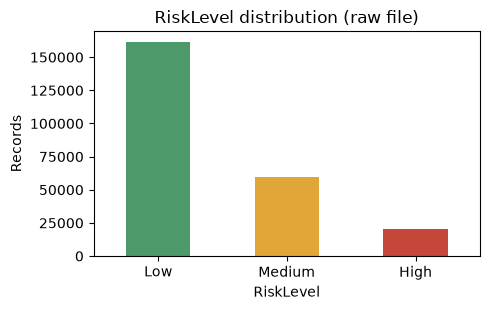

In [9]:
import matplotlib.pyplot as plt

LEVELS = ["Low", "Medium", "High"]
target_counts = raw["RiskLevel"].value_counts().reindex(LEVELS)
display(pd.DataFrame({"Records": target_counts, "Share (%)": (target_counts / len(raw) * 100).round(1)}))

ax = target_counts.plot.bar(color=["#4c9a6a", "#e0a63a", "#c4473a"], rot=0, figsize=(5, 3.2))
ax.set_title("RiskLevel distribution (raw file)")
ax.set_ylabel("Records")
plt.tight_layout()
plt.show()

The classes are imbalanced: High is fewer than one in ten records. A model that always answered "Low" would already be
about 67% accurate, which is why accuracy alone is not a fair measure here.

### 2.6 Target and candidate input features
Identifier columns are left out of the inputs. They describe *which* record it is, not *why* it is risky, and
`HouseholdID` or the coordinates would let the model memorize households. The values in `label_audit.csv` (risk
score, vulnerability score, event hazard) are also never used as inputs, because the label is calculated directly from
them.

In [10]:
TARGET = "RiskLevel"
ID_COLS = ["HouseholdID", "Barangay", "Latitude", "Longitude", "EventDate"]
FEATURE_GROUPS = {
    "Household": ["Age", "HousingMaterial", "HouseMembers", "ChildrenCount", "ElderCount", "PWDCount"],
    "Terrain at the house": ["ElevationMeters", "SlopeDegrees", "DistanceToWaterwayM", "LocationType",
                             "LandCoverType", "HistoricalWaterOccurrencePct"],
    "Flood hazard": ["FloodHazard5yr", "FloodHazard25yr", "FloodHazard100yr",
                     "HouseFloodHazard5yr", "HouseFloodHazard25yr", "HouseFloodHazard100yr",
                     "MGBFloodSusceptibility"],
    "Rainfall": ["Rainfall24hMm", "Rainfall3DayMm", "Rainfall7DayMm"],
}
FEATURES = [c for cols in FEATURE_GROUPS.values() for c in cols]
CATEGORICAL = [c for c in FEATURES if raw[c].dtype == object or str(raw[c].dtype) in ("string", "str", "category")]
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]

assert set(FEATURES) | set(ID_COLS) | {TARGET} == set(raw.columns)
print(f"{len(FEATURES)} candidate inputs: {len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical")
pd.DataFrame([(g, c, "categorical" if c in CATEGORICAL else "numeric")
              for g, cols in FEATURE_GROUPS.items() for c in cols],
             columns=["Group", "Feature", "Type"])

22 candidate inputs: 12 numeric, 10 categorical


,Group,Feature,Type
0,Household,Age,numeric
1,Household,HousingMaterial,categorical
2,Household,HouseMembers,numeric
3,Household,ChildrenCount,numeric
4,Household,ElderCount,numeric
5,Household,PWDCount,numeric
6,Terrain at the house,ElevationMeters,numeric
7,Terrain at the house,SlopeDegrees,numeric
8,Terrain at the house,DistanceToWaterwayM,numeric
9,Terrain at the house,LocationType,categorical


### 2.7 Numeric features

In [11]:
raw[NUMERIC].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,237581.0,55.46,16.57,18.00,43.00,56.00,69.00,90.00
HouseMembers,241200.0,4.34,2.24,1.00,3.00,4.00,6.00,12.00
ChildrenCount,241200.0,0.99,1.06,0.00,0.00,1.00,2.00,7.00
ElderCount,241200.0,0.41,0.63,0.00,0.00,0.00,1.00,4.00
PWDCount,241200.0,0.12,0.35,0.00,0.00,0.00,0.00,3.00
ElevationMeters,241200.0,11.57,5.98,1.63,7.25,10.02,14.68,35.89
SlopeDegrees,239263.0,1.70,1.30,0.01,0.81,1.38,2.26,12.80
DistanceToWaterwayM,241200.0,293.67,208.72,0.00,123.69,256.32,408.04,1260.00
HistoricalWaterOccurrencePct,241200.0,0.07,1.54,0.00,0.00,0.00,0.00,64.00
Rainfall24hMm,241200.0,73.92,60.83,0.19,16.52,63.73,126.81,226.13


### 2.8 Categorical features

In [12]:
for c in CATEGORICAL:
    print(f"{c:24s}", raw[c].value_counts(dropna=False).to_dict())

HousingMaterial          {'Concrete': 96992, 'SemiConcrete': 94306, 'LightMaterials': 47492, nan: 2410}
LocationType             {'Inland': 102248, 'NearWaterway': 91494, 'Riverside': 47458}
LandCoverType            {'TreeCover': 118391, 'BuiltUp': 111602, 'Cropland': 5489, 'Grassland': 5177, 'BareSparseVegetation': 541}
FloodHazard5yr           {'Low': 215632, 'Medium': 18847, 'None': 5757, 'High': 964}
FloodHazard25yr          {'Low': 168473, 'Medium': 71763, 'High': 964}
FloodHazard100yr         {'Medium': 149275, 'Low': 85042, 'High': 6883}
HouseFloodHazard5yr      {'None': 180888, 'Low': 42003, 'Medium': 16353, 'High': 1956}
HouseFloodHazard25yr     {'None': 148571, 'Low': 54062, 'Medium': 33538, 'High': 5029}
HouseFloodHazard100yr    {'None': 126955, 'Low': 60212, 'Medium': 47830, 'High': 6203}
MGBFloodSusceptibility   {'NotMapped': 131458, 'Moderate': 79146, 'High': 30596}


### 2.9 Records per household
Each household appears once for every rainfall event. This affects how the data must be split (see 2.12).

In [13]:
per_household = raw.drop_duplicates().groupby("HouseholdID").size()
print("Households:", f"{per_household.size:,}")
print("Records per household:", per_household.value_counts().to_dict())

Households: 8,000
Records per household: {30: 8000}


### 2.10 Cleaning
| Step | Decision | Reason |
|---|---|---|
| 1 | Drop exact duplicate rows | They repeat a record that is already present |
| 2 | Remove households with any missing value, rather than impute | Household details feed the label, so an imputed value would describe a household that does not exist, and its label would no longer match its inputs |
| 3 | Recompute wrong labels from the documented rule (risk score cut-offs 15 and 40) | Some labels were changed to a neighbouring level; the rule gives the correct one |
| 4 | Restore `Age` to whole numbers | It became decimal only because of the missing values |

In [14]:
log = [("Raw file", len(raw), raw.HouseholdID.nunique())]

# Step 1: duplicates
step1 = raw.drop_duplicates().reset_index(drop=True)
log.append(("After removing duplicates", len(step1), step1.HouseholdID.nunique()))

# Step 2: households with missing values
incomplete = step1.loc[step1.isna().any(axis=1), "HouseholdID"].unique()
step2 = step1[~step1.HouseholdID.isin(incomplete)].reset_index(drop=True)
log.append(("After removing incomplete households", len(step2), step2.HouseholdID.nunique()))

# Step 3: recompute labels from the rule
audit = pd.read_csv(os.path.join(DATA_DIR, "label_audit.csv"), keep_default_na=False,
                    usecols=["HouseholdID", "EventDate", "RiskScore"])
step3 = step2.merge(audit, on=["HouseholdID", "EventDate"], how="left", validate="one_to_one")
assert step3.RiskScore.notna().all()
rule_label = pd.cut(step3.RiskScore, [-np.inf, 15, 40, np.inf], right=False, labels=LEVELS).astype(str)
labels_fixed = int((rule_label != step3.RiskLevel).sum())
step3["RiskLevel"] = rule_label
step3 = step3.drop(columns="RiskScore")

# Step 4: Age back to integer
step3["Age"] = step3["Age"].astype(int)
clean_nb = step3
log.append(("After correcting labels", len(clean_nb), clean_nb.HouseholdID.nunique()))

print(f"Incomplete households removed: {len(incomplete)}")
print(f"Labels corrected            : {labels_fixed:,}")
pd.DataFrame(log, columns=["Step", "Rows", "Households"])

Incomplete households removed: 263
Labels corrected            : 1,181


,Step,Rows,Households
0,Raw file,241200,8000
1,After removing duplicates,240000,8000
2,After removing incomplete households,232110,7737
3,After correcting labels,232110,7737


### 2.11 Check the result against the published clean file

In [15]:
published = pd.read_csv(os.path.join(DATA_DIR, "agap_noah_dataset.csv"), keep_default_na=False)
print("Same shape  :", clean_nb.shape == published.shape, clean_nb.shape)
print("Same columns:", list(clean_nb.columns) == list(published.columns))
print("Missing values left:", int(clean_nb.isna().sum().sum()))

same_inputs = (clean_nb.drop(columns=TARGET).astype(str) == published.drop(columns=TARGET).astype(str)).all().all()
label_match = (clean_nb[TARGET] == published[TARGET])
print("All input values identical:", bool(same_inputs))
print(f"Labels identical: {label_match.sum():,} of {len(label_match):,}")

diff = published.loc[~label_match, ["HouseholdID", "EventDate", TARGET]].merge(
    pd.read_csv(os.path.join(DATA_DIR, "label_audit.csv"), keep_default_na=False,
                usecols=["HouseholdID", "EventDate", "RiskScore"]), on=["HouseholdID", "EventDate"])
diff

Same shape  : True (232110, 28)
Same columns: True
Missing values left: 0


All input values identical: True
Labels identical: 232,109 of 232,110


,HouseholdID,EventDate,RiskLevel,RiskScore
0,AGAP-SCL-02548,2022-10-29,Medium,40.0


The notebook's cleaning reproduces the published clean file exactly, apart from the row(s) shown above. In that case the
audit file stores the risk score rounded to four decimals, so a score just under the High cut-off (40) is saved as
`40.0` and cannot be told apart from the boundary. The published file was labelled from the unrounded score, so it is the
one used for modelling in Part 3.

### 2.12 Encoding and splitting plan

**Encoding.** The 10 categorical inputs are converted to the pandas `category` type. Scikit-learn's
`HistGradientBoostingClassifier` handles categories natively (`categorical_features="from_dtype"`), so one-hot encoding
is not needed. Tree models are not affected by the scale of a feature, so no scaling is applied.

**Splitting.** Every household appears 30 times, once per rain event. A plain random split would put the same house in
both training and test sets, so the model would be tested on households it has already seen. The data is therefore
split **by household**:
* 80/20 hold-out split with `GroupShuffleSplit` (`random_state=42`)
* 5-fold cross-validation with `GroupKFold` as a second check

**Class imbalance.** Training uses `class_weight="balanced"`, so a mistake on a Medium or High record costs more than a
mistake on a Low record. Results are reported with macro F1 and per-class recall.

---
# Part 3 · Week 3: Initial Machine Learning Model Development

### 3.1 Preprocessing

In [16]:
data = published.copy()
X = data[FEATURES].copy()
y = data[TARGET]
groups = data["HouseholdID"]

for c in CATEGORICAL:
    X[c] = X[c].astype("category")

assert not set(ID_COLS) & set(X.columns), "identifier columns must not be inputs"
assert X.isna().sum().sum() == 0
print("X:", X.shape, "| y:", y.shape)
print("Categorical inputs:", CATEGORICAL)
X.dtypes.astype(str).value_counts()

X: (232110, 22) | y: (232110,)
Categorical inputs: ['HousingMaterial', 'LocationType', 'LandCoverType', 'FloodHazard5yr', 'FloodHazard25yr', 'FloodHazard100yr', 'HouseFloodHazard5yr', 'HouseFloodHazard25yr', 'HouseFloodHazard100yr', 'MGBFloodSusceptibility']


category    10
float64      7
int64        5
Name: count, dtype: int64

### 3.2 Train/test split (grouped by household)

In [17]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

overlap = set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])
print(f"Training rows: {len(train_idx):,}  ({groups.iloc[train_idx].nunique():,} households)")
print(f"Test rows    : {len(test_idx):,}  ({groups.iloc[test_idx].nunique():,} households)")
print("Households in both sets:", len(overlap))

pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()}).reindex(LEVELS)

Training rows: 185,670  (6,189 households)
Test rows    : 46,440  (1,548 households)
Households in both sets: 0


,Train,Test
RiskLevel,,
Low,124490,31547
Medium,45399,11165
High,15781,3728


### 3.3 Baseline model
`HistGradientBoostingClassifier` was chosen as the baseline because it handles a mix of numeric and categorical inputs
without extra encoding, trains quickly on 185,000 rows, and supports class weights.

In [18]:
import time
from sklearn.ensemble import HistGradientBoostingClassifier

def make_model(class_weight="balanced"):
    return HistGradientBoostingClassifier(categorical_features="from_dtype", max_iter=500,
                                          class_weight=class_weight, random_state=0)

start = time.time()
model = make_model().fit(X_train, y_train)
print(f"Trained in {time.time() - start:.0f} s, {model.n_iter_} boosting iterations")

Trained in 14 s, 488 boosting iterations


### 3.4 Evaluation on the test households

In [19]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, cohen_kappa_score,
                             confusion_matrix, matthews_corrcoef, precision_recall_fscore_support,
                             ConfusionMatrixDisplay)

def metrics(true, pred):
    p, r, f, s = precision_recall_fscore_support(true, pred, labels=LEVELS, zero_division=0)
    _, _, macro_f1, _ = precision_recall_fscore_support(true, pred, labels=LEVELS, average="macro", zero_division=0)
    _, _, weighted_f1, _ = precision_recall_fscore_support(true, pred, labels=LEVELS, average="weighted", zero_division=0)
    out = {"Accuracy": accuracy_score(true, pred), "BalancedAccuracy": balanced_accuracy_score(true, pred),
           "MacroF1": macro_f1, "WeightedF1": weighted_f1,
           "CohenKappa": cohen_kappa_score(true, pred), "MCC": matthews_corrcoef(true, pred)}
    for i, c in enumerate(LEVELS):
        out |= {f"Precision_{c}": p[i], f"Recall_{c}": r[i], f"F1_{c}": f[i]}
    return out

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred, labels=LEVELS, digits=3))
baseline = metrics(y_test, y_pred)
pd.Series(baseline).round(4).to_frame("Baseline (80/20 test)")

              precision    recall  f1-score   support

         Low      0.997     0.994     0.996     31547
      Medium      0.970     0.977     0.974     11165
        High      0.956     0.958     0.957      3728

    accuracy                          0.987     46440
   macro avg      0.974     0.977     0.975     46440
weighted avg      0.987     0.987     0.987     46440



,Baseline (80/20 test)
Accuracy,0.9872
BalancedAccuracy,0.9765
MacroF1,0.9755
WeightedF1,0.9873
CohenKappa,0.9731
MCC,0.9731
Precision_Low,0.9970
Recall_Low,0.9943
F1_Low,0.9957
Precision_Medium,0.9702


,pred Low,pred Medium,pred High
true Low,31367,180,0
true Medium,94,10907,164
true High,0,155,3573


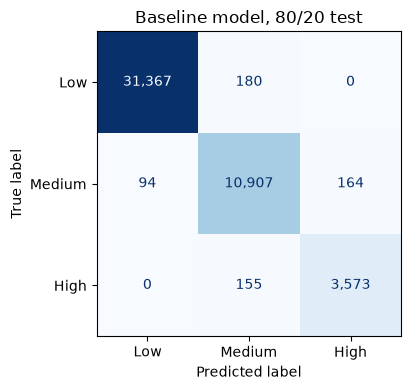

High predicted as Low: 0 | Low predicted as High: 0


In [20]:
cm = confusion_matrix(y_test, y_pred, labels=LEVELS)
cm_df = pd.DataFrame(cm, index=[f"true {c}" for c in LEVELS], columns=[f"pred {c}" for c in LEVELS])
display(cm_df)

fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(cm, display_labels=LEVELS).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
ax.set_title("Baseline model, 80/20 test")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

print("High predicted as Low:", cm[2, 0], "| Low predicted as High:", cm[0, 2])

### 3.5 Comparison models
Two variations are trained on the same split to see what matters:
* **Without class weights**, to see the effect of the imbalance handling.
* **Barangay hazard only**, which removes the hazard read at the house itself (`HouseFloodHazard*` and
  `MGBFloodSusceptibility`) and keeps only the barangay-level NOAH class.

In [21]:
HOUSE_LEVEL = ["HouseFloodHazard5yr", "HouseFloodHazard25yr", "HouseFloodHazard100yr", "MGBFloodSusceptibility"]
results = {"With class weights (baseline)": baseline}

pred = make_model(None).fit(X_train, y_train).predict(X_test)
results["Without class weights"] = metrics(y_test, pred)

pred_brgy = make_model().fit(X_train.drop(columns=HOUSE_LEVEL), y_train).predict(X_test.drop(columns=HOUSE_LEVEL))
results["Barangay hazard only"] = metrics(y_test, pred_brgy)
cm_brgy = pd.DataFrame(confusion_matrix(y_test, pred_brgy, labels=LEVELS),
                       index=[f"true {c}" for c in LEVELS], columns=[f"pred {c}" for c in LEVELS])

comparison = pd.DataFrame(results).T
comparison[["Accuracy", "BalancedAccuracy", "MacroF1", "F1_Low", "F1_Medium", "F1_High", "Recall_High"]].round(3)

,Accuracy,BalancedAccuracy,MacroF1,F1_Low,F1_Medium,F1_High,Recall_High
With class weights (baseline),0.987,0.977,0.975,0.996,0.974,0.957,0.958
Without class weights,0.988,0.974,0.977,0.996,0.975,0.960,0.950
Barangay hazard only,0.863,0.836,0.816,0.915,0.751,0.781,0.843


### 3.6 Five-fold cross-validation (grouped by household)
Set `RUN_CV = False` to skip this cell on a slow runtime (it trains five more models).

In [22]:
RUN_CV = True

cv_rows = []
if RUN_CV:
    for k, (a, b) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), 1):
        fold_pred = make_model().fit(X.iloc[a], y.iloc[a]).predict(X.iloc[b])
        cv_rows.append({"Fold": k, **metrics(y.iloc[b], fold_pred)})
        print(f"Fold {k}: macro F1 = {cv_rows[-1]['MacroF1']:.4f}, F1 High = {cv_rows[-1]['F1_High']:.4f}")
    cv = pd.DataFrame(cv_rows).set_index("Fold")
    summary = cv.agg(["mean", "std"]).T.round(4)
    display(summary.loc[["Accuracy", "MacroF1", "F1_Low", "F1_Medium", "F1_High", "Recall_High"]])

Fold 1: macro F1 = 0.9753, F1 High = 0.9573


Fold 2: macro F1 = 0.9756, F1 High = 0.9591


Fold 3: macro F1 = 0.9782, F1 High = 0.9646


Fold 4: macro F1 = 0.9748, F1 High = 0.9579


Fold 5: macro F1 = 0.9743, F1 High = 0.9555


,mean,std
Accuracy,0.9867,0.0006
MacroF1,0.9756,0.0015
F1_Low,0.9953,0.0002
F1_Medium,0.9728,0.0013
F1_High,0.9589,0.0034
Recall_High,0.9670,0.0047


### 3.7 Which inputs the model relies on
Permutation importance: each input is shuffled in turn on a sample of test households, and the drop in macro F1 is
recorded. A large drop means the model depends on that input.

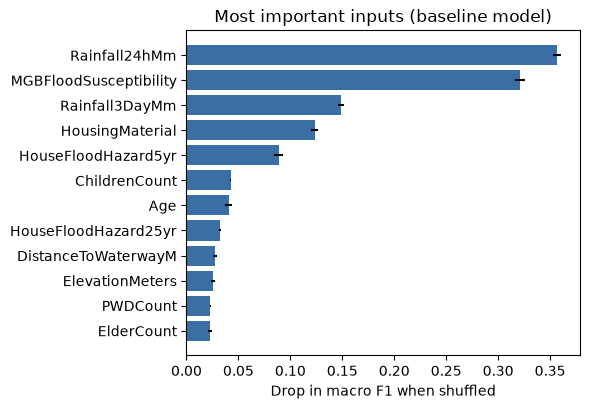

,Input,MacroF1Drop,SD
0,Rainfall24hMm,0.3566,0.0041
1,MGBFloodSusceptibility,0.3208,0.0050
2,Rainfall3DayMm,0.1488,0.0025
3,HousingMaterial,0.1233,0.0030
4,HouseFloodHazard5yr,0.0886,0.0043
5,ChildrenCount,0.0425,0.0008
6,Age,0.0405,0.0033
7,HouseFloodHazard25yr,0.0322,0.0013
8,DistanceToWaterwayM,0.0274,0.0016
9,ElevationMeters,0.0255,0.0016


In [23]:
from sklearn.inspection import permutation_importance

RUN_IMPORTANCE = True

if RUN_IMPORTANCE:
    sample = X_test.sample(10_000, random_state=0)
    imp = permutation_importance(model, sample, y_test.loc[sample.index], scoring="f1_macro",
                                 n_repeats=3, random_state=0, n_jobs=-1)
    importance = (pd.DataFrame({"Input": sample.columns, "MacroF1Drop": imp.importances_mean,
                                "SD": imp.importances_std})
                  .sort_values("MacroF1Drop", ascending=False).reset_index(drop=True))
    top = importance.head(12).iloc[::-1]
    fig, ax = plt.subplots(figsize=(6, 4.2))
    ax.barh(top.Input, top.MacroF1Drop, xerr=top.SD, color="#3b6ea5")
    ax.set_xlabel("Drop in macro F1 when shuffled")
    ax.set_title("Most important inputs (baseline model)")
    plt.tight_layout()
    fig.savefig(os.path.join(OUT_DIR, "feature_importance.png"), dpi=150)
    plt.show()
    display(importance.round(4).head(12))

### 3.8 Save predictions and outputs

In [24]:
import joblib

proba = model.predict_proba(X_test)
predictions = data.iloc[test_idx][["HouseholdID", "Barangay", "EventDate"]].copy()
predictions["TrueRiskLevel"] = y_test.values
predictions["PredictedRiskLevel"] = y_pred
for i, c in enumerate(model.classes_):
    predictions[f"Prob_{c}"] = proba[:, i].round(4)
predictions["Correct"] = predictions.TrueRiskLevel == predictions.PredictedRiskLevel

predictions.to_csv(os.path.join(OUT_DIR, "test_predictions.csv"), index=False)
comparison.round(4).to_csv(os.path.join(OUT_DIR, "model_metrics_80_20.csv"), index_label="Model")
cm_df.to_csv(os.path.join(OUT_DIR, "confusion_matrix.csv"))
cm_brgy.to_csv(os.path.join(OUT_DIR, "confusion_matrix_barangay_only.csv"))
if cv_rows:
    cv.round(4).to_csv(os.path.join(OUT_DIR, "cross_validation_5fold.csv"))
if RUN_IMPORTANCE:
    importance.round(4).to_csv(os.path.join(OUT_DIR, "feature_importance.csv"), index=False)
joblib.dump({"model": model, "features": FEATURES, "categorical": CATEGORICAL,
             "categories": {c: list(X[c].cat.categories) for c in CATEGORICAL}},
            os.path.join(OUT_DIR, "baseline_model.joblib"))

print("Saved files:")
for f in sorted(os.listdir(OUT_DIR)):
    print(f"  {f:38s} {os.path.getsize(os.path.join(OUT_DIR, f)) / 1024:9.1f} KB")
predictions.head()

Saved files:
  baseline_model.joblib                     5924.0 KB
  confusion_matrix.csv                         0.1 KB
  confusion_matrix.png                        26.3 KB
  confusion_matrix_barangay_only.csv           0.1 KB
  cross_validation_5fold.csv                   0.7 KB
  feature_importance.csv                       0.7 KB
  feature_importance.png                      49.2 KB
  model_metrics_80_20.csv                      0.5 KB
  test_predictions.csv                      2975.9 KB


,HouseholdID,Barangay,EventDate,TrueRiskLevel,PredictedRiskLevel,Prob_High,Prob_Low,Prob_Medium,Correct
0,AGAP-SCL-00001,Gatid,1993-12-27,Medium,Medium,0.0,0.0006,0.9994,True
1,AGAP-SCL-00001,Gatid,1994-10-21,Low,Low,0.0,0.9810,0.0190,True
2,AGAP-SCL-00001,Gatid,1995-02-02,Low,Low,0.0,1.0000,0.0000,True
3,AGAP-SCL-00001,Gatid,1996-02-13,Low,Low,0.0,1.0000,0.0000,True
4,AGAP-SCL-00001,Gatid,1999-08-01,Low,Low,0.0,1.0000,0.0000,True


### 3.9 Example: predicting a single household

In [25]:
saved = joblib.load(os.path.join(OUT_DIR, "baseline_model.joblib"))
example = X_test.iloc[[0]]
print("Inputs:")
print(example.T.to_string(header=False))
print("\nPredicted :", saved["model"].predict(example)[0])
print("Actual    :", y_test.iloc[0])
print("Probabilities:", dict(zip(saved["model"].classes_, saved["model"].predict_proba(example)[0].round(3))))

Inputs:
Age                                  76
HousingMaterial                Concrete
HouseMembers                          6
ChildrenCount                         2
ElderCount                            3
PWDCount                              0
ElevationMeters                    4.33
SlopeDegrees                       1.47
DistanceToWaterwayM              1260.0
LocationType                     Inland
LandCoverType                 TreeCover
HistoricalWaterOccurrencePct        0.0
FloodHazard5yr                      Low
FloodHazard25yr                     Low
FloodHazard100yr                    Low
HouseFloodHazard5yr                None
HouseFloodHazard25yr               None
HouseFloodHazard100yr              None
MGBFloodSusceptibility         Moderate
Rainfall24hMm                     78.14
Rainfall3DayMm                    93.06
Rainfall7DayMm                    145.2

Predicted : Medium
Actual    : Medium
Probabilities: {'High': np.float64(0.0), 'Low': np.float64(0.001), 'Mediu

---
# Part 4 · Week 4: Model Evaluation and Performance Comparison

### 4.1 Choice of metrics
| Metric | Why it is used here |
|---|---|
| **Macro F1** (main metric) | The average of the F1 scores of Low, Medium and High, with each level counting equally. It cannot be inflated by predicting Low well. |
| **Recall on High** | Out of the households that are truly High risk, the share the model catches. A missed High household is the costliest mistake for evacuation planning. |
| Precision and F1 per level | Shows whether one level is handled worse than the others |
| Balanced accuracy, Cohen's kappa, MCC | Summary scores that account for class imbalance and for chance agreement |
| Accuracy | Reported for completeness only. A model that always says Low scores 67.9% on this test set. |
| Confusion matrix | Shows *which* levels are confused. Confusing Low with High would be far worse than confusing neighbouring levels. |

### 4.2 Confidence intervals (bootstrap by household)
A single test score gives no idea of its uncertainty. The test households are resampled with replacement 300 times,
always keeping all 30 events of a household together, and the metrics are recalculated each time. The middle 95% of
these values is the 95% confidence interval.

In [26]:
CODE = {c: i for i, c in enumerate(LEVELS)}

def fast_scores(t_codes, p_codes):
    # macro F1, F1 per level and recall per level from integer-coded labels
    cm = np.bincount(t_codes * 3 + p_codes, minlength=9).reshape(3, 3)
    tp = np.diag(cm)
    prec = tp / np.maximum(cm.sum(axis=0), 1)
    rec = tp / np.maximum(cm.sum(axis=1), 1)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-12), 0)
    return f1.mean(), f1, rec

test_groups = groups.iloc[test_idx].to_numpy()
_, hh_code = np.unique(test_groups, return_inverse=True)
order = np.argsort(hh_code, kind="stable")
rows_by_household = np.split(order, np.cumsum(np.bincount(hh_code))[:-1])
y_test_codes = y_test.map(CODE).to_numpy()

def bootstrap_ci(pred, n_boot=300, seed=0):
    rng = np.random.default_rng(seed)
    p_codes = pd.Series(pred).map(CODE).to_numpy()
    stats = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(rows_by_household), len(rows_by_household))
        idx = np.concatenate([rows_by_household[k] for k in pick])
        m, f1, rec = fast_scores(y_test_codes[idx], p_codes[idx])
        stats.append((m, f1[2], rec[2]))
    lo, hi = np.percentile(np.array(stats), [2.5, 97.5], axis=0)
    point = fast_scores(y_test_codes, p_codes)
    return {"MacroF1": point[0], "MacroF1 95% CI": f"{lo[0]:.4f} – {hi[0]:.4f}",
            "F1_High": point[1][2], "F1_High 95% CI": f"{lo[1]:.4f} – {hi[1]:.4f}",
            "Recall_High": point[2][2], "Recall_High 95% CI": f"{lo[2]:.4f} – {hi[2]:.4f}"}

print("Accuracy of always predicting Low:", round((y_test == "Low").mean(), 4))
baseline_ci = bootstrap_ci(y_pred)
pd.Series(baseline_ci).to_frame("Baseline (gradient boosting)")

Accuracy of always predicting Low: 0.6793


,Baseline (gradient boosting)
MacroF1,0.975485
MacroF1 95% CI,0.9719 – 0.9794
F1_High,0.957267
F1_High 95% CI,0.9496 – 0.9657
Recall_High,0.958423
Recall_High 95% CI,0.9462 – 0.9689


### 4.3 Interpreting the baseline results
The label is computed from a risk score with cut-offs at 15 (Low/Medium) and 40 (Medium/High). The audit file keeps that
score for every record. It is used here **only to explain the errors**, never as a model input. If the model has learned
the rule, its mistakes should sit close to the cut-offs, where a small difference in the inputs moves a record to the
next level.

Baseline errors: 593 of 46,440 test records (1.28%)
  errors with a risk score within 1 point(s) of a cut-off: 79.4%   (all test records: 4.1%)
  errors with a risk score within 3 point(s) of a cut-off: 98.7%   (all test records: 12.8%)
  errors with a risk score within 5 point(s) of a cut-off: 99.5%   (all test records: 21.9%)


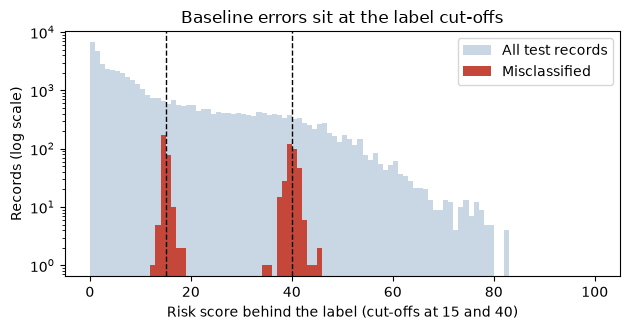

In [27]:
audit_info = pd.read_csv(os.path.join(DATA_DIR, "label_audit.csv"), keep_default_na=False,
                         usecols=["HouseholdID", "EventDate", "EventType", "EffectiveRainMm", "RiskScore"])
test_info = data.iloc[test_idx][["HouseholdID", "Barangay", "EventDate", "HousingMaterial", "LocationType",
                                 "ElderCount", "PWDCount"]].merge(audit_info, on=["HouseholdID", "EventDate"], how="left")
assert len(test_info) == len(test_idx) and test_info.RiskScore.notna().all()
test_info["DistanceToCutoff"] = np.minimum((test_info.RiskScore - 15).abs(), (test_info.RiskScore - 40).abs())
test_info["BaselineCorrect"] = (y_pred == y_test.to_numpy())

wrong = test_info[~test_info.BaselineCorrect]
print(f"Baseline errors: {len(wrong):,} of {len(test_info):,} test records ({len(wrong) / len(test_info):.2%})")
for d in (1, 3, 5):
    print(f"  errors with a risk score within {d} point(s) of a cut-off: {(wrong.DistanceToCutoff <= d).mean():.1%}"
          f"   (all test records: {(test_info.DistanceToCutoff <= d).mean():.1%})")

fig, ax = plt.subplots(figsize=(6.4, 3.4))
bins = np.arange(0, 101, 1)
ax.hist(test_info.RiskScore, bins=bins, color="#c9d6e3", label="All test records")
ax.hist(wrong.RiskScore, bins=bins, color="#c4473a", label="Misclassified")
for cut in (15, 40):
    ax.axvline(cut, color="black", lw=1, ls="--")
ax.set_yscale("log")
ax.set_xlabel("Risk score behind the label (cut-offs at 15 and 40)")
ax.set_ylabel("Records (log scale)")
ax.set_title("Baseline errors sit at the label cut-offs")
ax.legend()
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "errors_vs_cutoffs.png"), dpi=150)
plt.show()

In [28]:
err_by_type = (test_info.assign(Error=~test_info.BaselineCorrect)
               .groupby("EventType")["Error"].agg(["mean", "sum", "size"])
               .reindex(["Light", "Moderate", "Heavy", "Extreme"]))
err_by_type.columns = ["Error rate", "Errors", "Records"]
err_by_type.style.format({"Error rate": "{:.2%}"})

,Error rate,Errors,Records
EventType,,,
Light,0.00%,0,9288
Moderate,0.17%,16,9288
Heavy,1.39%,193,13932
Extreme,2.76%,384,13932


### 4.4 Comparison with a second and a third model
* **Random Forest:** a different tree ensemble (bagging instead of boosting). Categories are one-hot encoded and the classes are weighted.
* **Logistic Regression:** a linear model, used as a simple reference. Categories are one-hot encoded, numbers are standardised and the classes are weighted.

All three models use the same training and test households.

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

rf_model = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL)], remainder="passthrough"),
    RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced", n_jobs=-1, random_state=0))
lr_model = make_pipeline(
    ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL), ("num", StandardScaler(), NUMERIC)]),
    LogisticRegression(max_iter=2000, class_weight="balanced"))

compare_pred = {"Gradient boosting (baseline)": y_pred}
for name, m in [("Random Forest", rf_model), ("Logistic Regression", lr_model)]:
    start = time.time()
    m.fit(X_train, y_train)
    compare_pred[name] = m.predict(X_test)
    print(f"{name}: trained in {time.time() - start:.0f} s")

rows = []
for name, pred in compare_pred.items():
    full = metrics(y_test, pred)
    ci = bootstrap_ci(pred)
    rows.append({"Model": name, "Accuracy": full["Accuracy"], "BalancedAccuracy": full["BalancedAccuracy"],
                 "MacroF1": full["MacroF1"], "MacroF1 95% CI": ci["MacroF1 95% CI"],
                 "F1_Low": full["F1_Low"], "F1_Medium": full["F1_Medium"], "F1_High": full["F1_High"],
                 "Recall_High": full["Recall_High"], "Recall_High 95% CI": ci["Recall_High 95% CI"],
                 "CohenKappa": full["CohenKappa"], "MCC": full["MCC"]})
model_comparison = pd.DataFrame(rows).set_index("Model")
model_comparison.round(4)

Random Forest: trained in 7 s


Logistic Regression: trained in 5 s


,Accuracy,BalancedAccuracy,MacroF1,MacroF1 95% CI,F1_Low,F1_Medium,F1_High,Recall_High,Recall_High 95% CI,CohenKappa,MCC
Model,,,,,,,,,,,
Gradient boosting (baseline),0.9872,0.9765,0.9755,0.9719 – 0.9794,0.9957,0.9735,0.9573,0.9584,0.9462 – 0.9689,0.9731,0.9731
Random Forest,0.9735,0.9495,0.9491,0.9448 – 0.9541,0.9910,0.9455,0.9109,0.9050,0.8876 – 0.9210,0.9444,0.9444
Logistic Regression,0.8894,0.8856,0.8458,0.8380 – 0.8533,0.9384,0.7923,0.8068,0.9166,0.9022 – 0.9283,0.7782,0.7817


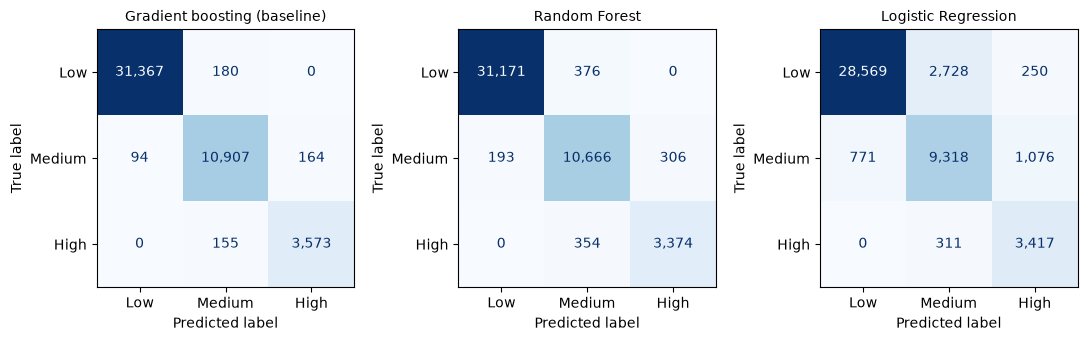

Gradient boosting (baseline)   High predicted as Low:    0   Low predicted as High:    0
Random Forest                  High predicted as Low:    0   Low predicted as High:    0


Logistic Regression            High predicted as Low:    0   Low predicted as High:  250


In [30]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (name, pred) in zip(axes, compare_pred.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=LEVELS), display_labels=LEVELS).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=",")
    ax.set_title(name, fontsize=10)
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "confusion_matrices_comparison.png"), dpi=150)
plt.show()

for name, pred in compare_pred.items():
    cm_ = confusion_matrix(y_test, pred, labels=LEVELS)
    print(f"{name:30s} High predicted as Low: {cm_[2, 0]:>4}   Low predicted as High: {cm_[0, 2]:>4}")

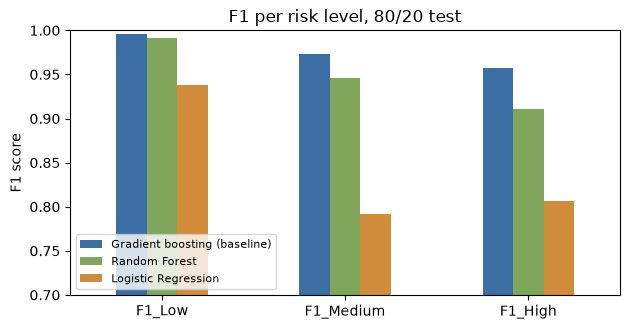

In [31]:
ax = model_comparison[["F1_Low", "F1_Medium", "F1_High"]].T.plot.bar(rot=0, figsize=(6.4, 3.4),
                                                                      color=["#3b6ea5", "#7fa65a", "#d08c3a"])
ax.set_ylim(0.7, 1.0)
ax.set_ylabel("F1 score")
ax.set_title("F1 per risk level, 80/20 test")
ax.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "model_comparison_f1.png"), dpi=150)
plt.show()

### 4.5 Save the comparison outputs

In [32]:
model_comparison.round(4).to_csv(os.path.join(OUT_DIR, "model_comparison.csv"))
comparison_predictions = data.iloc[test_idx][["HouseholdID", "Barangay", "EventDate"]].copy()
comparison_predictions["TrueRiskLevel"] = y_test.values
for name, pred in compare_pred.items():
    comparison_predictions[name] = pred
comparison_predictions.to_csv(os.path.join(OUT_DIR, "comparison_predictions.csv"), index=False)
print("Saved model_comparison.csv and comparison_predictions.csv")

Saved model_comparison.csv and comparison_predictions.csv


---
# Part 5 · Week 5: Model Optimization and Error Analysis

### 5.1 A validation split for tuning
The test households must stay untouched until the final check. If they were used to choose between settings, the
final test score would be biased upward. So 20% of the **training** households are set aside as a validation set, and
every choice in this part is made on that set. The test set is used once, in 5.5.

In [33]:
sub_tr, sub_val = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=7).split(
    X_train, y_train, groups.iloc[train_idx]))
print(f"Tuning-train rows: {len(sub_tr):,}   Validation rows: {len(sub_val):,}")
assert not set(groups.iloc[train_idx].iloc[sub_tr]) & set(groups.iloc[train_idx].iloc[sub_val])

Tuning-train rows: 148,530   Validation rows: 37,140


### 5.2 Change 1 (preprocessing): two engineered features
* **EffectiveRainMm** = 24-hour rain + 30% of the rain in the two days before. Wet ground floods sooner, so rain that
  fell before the event day matters too. The model only receives the 24-hour and 3-day totals, so it would have to
  discover this combination by itself through many tree splits.
* **Dependents** = children + elderly + persons with disability. Each group needs help during an evacuation.

Both features are calculated from existing inputs only. They add no outside information, so there is no leakage.

In [34]:
def add_features(frame):
    out = frame.copy()
    out["EffectiveRainMm"] = out["Rainfall24hMm"] + 0.3 * (out["Rainfall3DayMm"] - out["Rainfall24hMm"])
    out["Dependents"] = out["ChildrenCount"] + out["ElderCount"] + out["PWDCount"]
    return out

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)

def tuned_model(learning_rate=0.1, max_leaf_nodes=31):
    return HistGradientBoostingClassifier(categorical_features="from_dtype", max_iter=500, class_weight="balanced",
                                          learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes, random_state=0)

def val_scores(m, Xtr, Xval):
    m.fit(Xtr, y_train.iloc[sub_tr])
    s = metrics(y_train.iloc[sub_val], m.predict(Xval))
    return {"MacroF1": s["MacroF1"], "F1_High": s["F1_High"], "Recall_High": s["Recall_High"], "Iterations": m.n_iter_}

tuning_rows, tuning_models = [], {}
for fs_name, Xs in [("Original 22 inputs", X_train), ("+ engineered features", X_train_fe)]:
    m = tuned_model()
    tuning_rows.append({"Features": fs_name, "learning_rate": 0.1, "max_leaf_nodes": 31,
                        **val_scores(m, Xs.iloc[sub_tr], Xs.iloc[sub_val])})
    tuning_models[(fs_name, 0.1, 31)] = m
    print(tuning_rows[-1])
best_fs = max(tuning_rows, key=lambda r: r["MacroF1"])["Features"]
print("\nFeature set kept:", best_fs)

{'Features': 'Original 22 inputs', 'learning_rate': 0.1, 'max_leaf_nodes': 31, 'MacroF1': 0.9710888448096625, 'F1_High': np.float64(0.9504643962848297), 'Recall_High': np.float64(0.9608763693270735), 'Iterations': 351}


{'Features': '+ engineered features', 'learning_rate': 0.1, 'max_leaf_nodes': 31, 'MacroF1': 0.9723454634956371, 'F1_High': np.float64(0.9524252285758562), 'Recall_High': np.float64(0.9618153364632238), 'Iterations': 320}

Feature set kept: + engineered features


### 5.3 Change 2 (model settings): learning rate and tree size
`learning_rate` controls how much each new tree corrects the previous ones, and `max_leaf_nodes` controls how detailed
each tree is. Smaller trees generalise better when the pattern is smooth. A small grid is tried on the feature set kept
in 5.2. The default setting (0.1, 31) is already in the table.

In [35]:
Xs = X_train_fe if best_fs.startswith("+") else X_train
for lr_, leaves in [(0.05, 15), (0.1, 15), (0.2, 15), (0.2, 31)]:
    m = tuned_model(lr_, leaves)
    tuning_rows.append({"Features": best_fs, "learning_rate": lr_, "max_leaf_nodes": leaves,
                        **val_scores(m, Xs.iloc[sub_tr], Xs.iloc[sub_val])})
    tuning_models[(best_fs, lr_, leaves)] = m
    print(tuning_rows[-1])

tuning = pd.DataFrame(tuning_rows).sort_values("MacroF1", ascending=False).reset_index(drop=True)
tuning.to_csv(os.path.join(OUT_DIR, "tuning_results.csv"), index=False)
best = tuning.iloc[0]
FINAL_FS, FINAL_LR, FINAL_LEAVES = best.Features, float(best.learning_rate), int(best.max_leaf_nodes)
USE_ENGINEERED = FINAL_FS.startswith("+")
print(f"\nChosen on validation: {FINAL_FS}, learning_rate={FINAL_LR}, max_leaf_nodes={FINAL_LEAVES}")
tuning.round(4)

{'Features': '+ engineered features', 'learning_rate': 0.05, 'max_leaf_nodes': 15, 'MacroF1': 0.972594911549416, 'F1_High': np.float64(0.956959706959707), 'Recall_High': np.float64(0.9812206572769953), 'Iterations': 500}


{'Features': '+ engineered features', 'learning_rate': 0.1, 'max_leaf_nodes': 15, 'MacroF1': 0.9744265534352282, 'F1_High': np.float64(0.9572044334975369), 'Recall_High': np.float64(0.9730829420970266), 'Iterations': 500}


{'Features': '+ engineered features', 'learning_rate': 0.2, 'max_leaf_nodes': 15, 'MacroF1': 0.9748513857733311, 'F1_High': np.float64(0.9576466964423225), 'Recall_High': np.float64(0.9730829420970266), 'Iterations': 281}


{'Features': '+ engineered features', 'learning_rate': 0.2, 'max_leaf_nodes': 31, 'MacroF1': 0.9716057721793256, 'F1_High': np.float64(0.9510273443534683), 'Recall_High': np.float64(0.9633802816901409), 'Iterations': 198}

Chosen on validation: + engineered features, learning_rate=0.2, max_leaf_nodes=15


,Features,learning_rate,max_leaf_nodes,MacroF1,F1_High,Recall_High,Iterations
0,+ engineered features,0.20,15,0.9749,0.9576,0.9731,281
1,+ engineered features,0.10,15,0.9744,0.9572,0.9731,500
2,+ engineered features,0.05,15,0.9726,0.9570,0.9812,500
3,+ engineered features,0.10,31,0.9723,0.9524,0.9618,320
4,+ engineered features,0.20,31,0.9716,0.9510,0.9634,198
5,Original 22 inputs,0.10,31,0.9711,0.9505,0.9609,351


### 5.4 Overfitting check
Two checks:
1. The score on the rows the model was trained on, compared with the score on households it has never seen. A large gap means the model memorised its training data.
2. The validation score after each boosting iteration. If the curve went back down after a peak, extra iterations would be hurting.

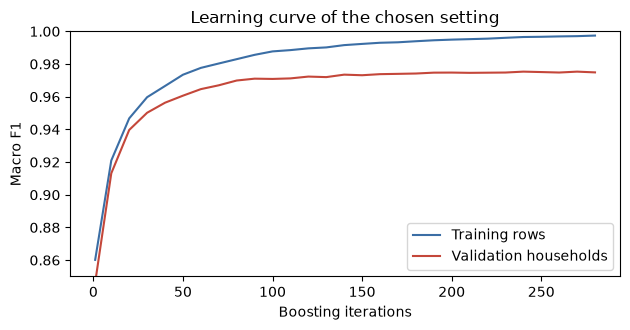

Final iteration: training 0.9974, validation 0.9749, gap 0.0225
Best validation score 0.9753 at iteration 240


In [36]:
curve_model = tuning_models[(FINAL_FS, FINAL_LR, FINAL_LEAVES)]
Xs_tr = (X_train_fe if USE_ENGINEERED else X_train).iloc[sub_tr]
Xs_val = (X_train_fe if USE_ENGINEERED else X_train).iloc[sub_val]
yv = y_train.iloc[sub_val].map(CODE).to_numpy()
sample_tr = np.random.default_rng(0).choice(len(sub_tr), 40_000, replace=False)
yt_s = y_train.iloc[sub_tr].iloc[sample_tr].map(CODE).to_numpy()

steps, train_curve, val_curve = [], [], []
for k, (p_tr, p_val) in enumerate(zip(curve_model.staged_predict(Xs_tr.iloc[sample_tr]),
                                      curve_model.staged_predict(Xs_val)), 1):
    if k % 10 == 0 or k == 1:
        steps.append(k)
        train_curve.append(fast_scores(yt_s, pd.Series(p_tr).map(CODE).to_numpy())[0])
        val_curve.append(fast_scores(yv, pd.Series(p_val).map(CODE).to_numpy())[0])

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(steps, train_curve, label="Training rows", color="#3b6ea5")
ax.plot(steps, val_curve, label="Validation households", color="#c4473a")
ax.set_xlabel("Boosting iterations")
ax.set_ylabel("Macro F1")
ax.set_ylim(0.85, 1.0)
ax.set_title("Learning curve of the chosen setting")
ax.legend()
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "learning_curve.png"), dpi=150)
plt.show()
print(f"Final iteration: training {train_curve[-1]:.4f}, validation {val_curve[-1]:.4f}, "
      f"gap {train_curve[-1] - val_curve[-1]:.4f}")
print(f"Best validation score {max(val_curve):.4f} at iteration {steps[int(np.argmax(val_curve))]}")

### 5.5 Final model: train on all training households, test once

Final model trained in 10 s, 372 iterations


,Accuracy,BalancedAccuracy,MacroF1,F1_Low,F1_Medium,F1_High,Recall_High,CohenKappa,MCC
Baseline (Week 3),0.9872,0.9765,0.9755,0.9957,0.9735,0.9573,0.9584,0.9731,0.9731
Final model,0.9890,0.9812,0.9791,0.9962,0.9773,0.9638,0.9689,0.9769,0.9770


Final model 95% CIs: {'MacroF1 95% CI': '0.9755 – 0.9828', 'F1_High 95% CI': '0.9558 – 0.9724', 'Recall_High 95% CI': '0.9574 – 0.9799'}
Overfitting check: macro F1 on training rows 0.9975, on test households 0.9791


,pred Low,pred Medium,pred High
true Low,31374,173,0
true Medium,65,10945,155
true High,0,116,3612


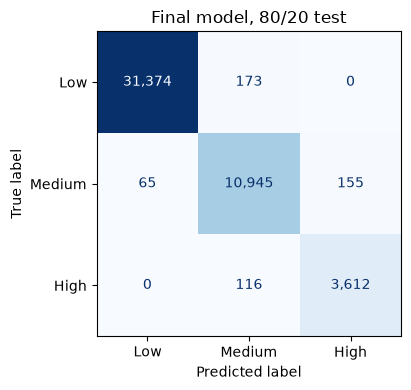

In [37]:
X_train_final = X_train_fe if USE_ENGINEERED else X_train
X_test_final = X_test_fe if USE_ENGINEERED else X_test
FINAL_FEATURES = list(X_train_final.columns)

start = time.time()
final_model = tuned_model(FINAL_LR, FINAL_LEAVES).fit(X_train_final, y_train)
print(f"Final model trained in {time.time() - start:.0f} s, {final_model.n_iter_} iterations")
final_pred = final_model.predict(X_test_final)
final_proba = final_model.predict_proba(X_test_final)

final_scores = metrics(y_test, final_pred)
final_ci = bootstrap_ci(final_pred)
train_scores = metrics(y_train, final_model.predict(X_train_final))
before_after = pd.DataFrame({"Baseline (Week 3)": baseline, "Final model": final_scores}).T
display(before_after[["Accuracy", "BalancedAccuracy", "MacroF1", "F1_Low", "F1_Medium", "F1_High",
                      "Recall_High", "CohenKappa", "MCC"]].round(4))
print("Final model 95% CIs:", {k: v for k, v in final_ci.items() if "CI" in k})
print(f"Overfitting check: macro F1 on training rows {train_scores['MacroF1']:.4f}, "
      f"on test households {final_scores['MacroF1']:.4f}")

final_cm = confusion_matrix(y_test, final_pred, labels=LEVELS)
final_cm_df = pd.DataFrame(final_cm, index=[f"true {c}" for c in LEVELS], columns=[f"pred {c}" for c in LEVELS])
display(final_cm_df)
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(final_cm, display_labels=LEVELS).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",")
ax.set_title("Final model, 80/20 test")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "final_confusion_matrix.png"), dpi=150)
plt.show()

### 5.6 Five-fold cross-validation of the final setting
The same household folds as in 3.6 are used, so each fold can be compared directly with the baseline.

In [38]:
final_cv_rows = []
if RUN_CV:
    X_all_final = add_features(X) if USE_ENGINEERED else X
    for k, (a, b) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), 1):
        fold_pred = tuned_model(FINAL_LR, FINAL_LEAVES).fit(X_all_final.iloc[a], y.iloc[a]).predict(X_all_final.iloc[b])
        final_cv_rows.append({"Fold": k, **metrics(y.iloc[b], fold_pred)})
    final_cv = pd.DataFrame(final_cv_rows).set_index("Fold")
    paired = pd.DataFrame({
        "Baseline macro F1": cv["MacroF1"], "Final macro F1": final_cv["MacroF1"],
        "Baseline F1 High": cv["F1_High"], "Final F1 High": final_cv["F1_High"],
        "Baseline recall High": cv["Recall_High"], "Final recall High": final_cv["Recall_High"]})
    paired.loc["Mean"] = paired.mean()
    paired.loc["SD"] = paired.iloc[:5].std()
    display(paired.round(4))
    print("Folds where the final model has the higher macro F1:",
          int((final_cv["MacroF1"] > cv["MacroF1"]).sum()), "of 5")
    print("Lowest fold F1 High, final model:", round(final_cv["F1_High"].min(), 4))

,Baseline macro F1,Final macro F1,Baseline F1 High,Final F1 High,Baseline recall High,Final recall High
Fold,,,,,,
1,0.9753,0.9791,0.9573,0.9652,0.9695,0.9769
2,0.9756,0.9799,0.9591,0.9673,0.9693,0.9766
3,0.9782,0.9818,0.9646,0.9714,0.9720,0.9785
4,0.9748,0.9811,0.9579,0.9699,0.9624,0.9729
5,0.9743,0.9778,0.9555,0.9622,0.9617,0.9720
Mean,0.9756,0.9799,0.9589,0.9672,0.9670,0.9754
SD,0.0015,0.0016,0.0034,0.0037,0.0047,0.0028


Folds where the final model has the higher macro F1: 5 of 5
Lowest fold F1 High, final model: 0.9622


### 5.7 Error analysis of the final model

In [39]:
test_info["FinalPred"] = final_pred
test_info["TrueRisk"] = y_test.to_numpy()
test_info["FinalCorrect"] = test_info.FinalPred == test_info.TrueRisk
final_wrong = test_info[~test_info.FinalCorrect]
print(f"Final model errors: {len(final_wrong):,} ({len(final_wrong) / len(test_info):.2%}); "
      f"baseline errors: {(~test_info.BaselineCorrect).sum():,}")
print(f"Errors within 3 points of a cut-off: {(final_wrong.DistanceToCutoff <= 3).mean():.1%}")
print(f"Largest distance from a cut-off among errors: {final_wrong.DistanceToCutoff.max():.2f} points")

print("\nDirection of the errors:")
display(pd.crosstab(final_wrong.TrueRisk, final_wrong.FinalPred).reindex(index=LEVELS, columns=LEVELS, fill_value=0))

print("Error rate by event type:")
display((1 - test_info.groupby("EventType")["FinalCorrect"].mean())
        .reindex(["Light", "Moderate", "Heavy", "Extreme"]).to_frame("Error rate").style.format("{:.2%}"))

Final model errors: 509 (1.10%); baseline errors: 593
Errors within 3 points of a cut-off: 98.2%
Largest distance from a cut-off among errors: 9.95 points

Direction of the errors:


FinalPred,Low,Medium,High
TrueRisk,,,
Low,0,173,0
Medium,65,0,155
High,0,116,0


Error rate by event type:


,Error rate
EventType,
Light,0.00%
Moderate,0.16%
Heavy,1.30%
Extreme,2.25%


### 5.8 Bias check: does the model work equally well for different groups?
If the model missed High-risk households more often in one group (for example, households with elderly members, or
one barangay), it would be unfair to that group in evacuation planning. Recall on High and macro F1 are compared across
groups.

In [40]:
def group_scores(col, values=None):
    rows = []
    for val, g in test_info.groupby(col):
        hi = g[g.TrueRisk == "High"]
        present = sorted(set(g.TrueRisk.map(CODE)))           # only levels that occur in this group
        f1 = fast_scores(g.TrueRisk.map(CODE).to_numpy(), g.FinalPred.map(CODE).to_numpy())[1]
        rows.append({col: val, "Records": len(g), "High records": len(hi),
                     "Accuracy": (g.TrueRisk == g.FinalPred).mean(),
                     "Macro F1 (levels present)": f1[present].mean(),
                     "Recall High": (hi.FinalPred == "High").mean() if len(hi) else np.nan})
    return pd.DataFrame(rows).set_index(col)

test_info["HasElderly"] = np.where(test_info.ElderCount > 0, "Yes", "No")
test_info["HasPWD"] = np.where(test_info.PWDCount > 0, "Yes", "No")
for col in ["HousingMaterial", "LocationType", "HasElderly", "HasPWD"]:
    display(group_scores(col).round(4))

by_brgy = group_scores("Barangay")
by_brgy_hi = by_brgy[by_brgy["High records"] >= 30]
print(f"Barangays: accuracy ranges from {by_brgy['Accuracy'].min():.4f} to {by_brgy['Accuracy'].max():.4f}")
print(f"Recall High, barangays with at least 30 High records: "
      f"{by_brgy_hi['Recall High'].min():.4f} to {by_brgy_hi['Recall High'].max():.4f}")
by_brgy.round(4).to_csv(os.path.join(OUT_DIR, "scores_by_barangay.csv"))
by_brgy.sort_values("Accuracy").head(5).round(4)

,Records,High records,Accuracy,Macro F1 (levels present),Recall High
HousingMaterial,,,,,
Concrete,18990,749,0.9892,0.9694,0.9426
LightMaterials,9150,1294,0.9854,0.9784,0.9791
SemiConcrete,18300,1685,0.9907,0.9824,0.9727


,Records,High records,Accuracy,Macro F1 (levels present),Recall High
LocationType,,,,,
Inland,19830,1012,0.9902,0.9774,0.9704
NearWaterway,18060,1626,0.9906,0.9822,0.9723
Riverside,8550,1090,0.9832,0.9735,0.9624


,Records,High records,Accuracy,Macro F1 (levels present),Recall High
HasElderly,,,,,
No,31020,2037,0.9892,0.9778,0.9656
Yes,15420,1691,0.9888,0.9804,0.9728


,Records,High records,Accuracy,Macro F1 (levels present),Recall High
HasPWD,,,,,
No,40680,3204,0.9895,0.9798,0.9682
Yes,5760,524,0.9856,0.9742,0.9733


Barangays: accuracy ranges from 0.9724 to 1.0000
Recall High, barangays with at least 30 High records: 0.7500 to 1.0000


,Records,High records,Accuracy,Macro F1 (levels present),Recall High
Barangay,,,,,
Santo Angel Sur,870,191,0.9724,0.9684,0.9267
Barangay II (Pob.),360,37,0.9778,0.9750,1.0000
Barangay III (Pob.),210,39,0.9810,0.9812,0.9744
Santo Angel Central,1590,370,0.9818,0.9788,0.9730
Santo Angel Norte,1260,398,0.9841,0.9826,0.9774


### 5.9 Limitations, risks and possible bias
1. **The labels come from a rule, not from observed floods.** The risk level is calculated with a documented formula
   (flood hazard × household vulnerability). The high scores show that the model reproduces this formula. They do not
   show that it predicts real flood damage. That would need recorded flood outcomes, which do not exist at household
   level for Santa Cruz.
2. **Household details are simulated.** Age, household size, housing material and dependents were generated, not
   surveyed. Their distributions may differ from the real population.
3. **Rainfall source.** NASA POWER is a gridded estimate, not a rain gauge. Its 2020 values are far above the ERA5
   reanalysis (6,663 mm against 2,917 mm for the year), and 6 of the 15 extreme events are from 2020.
4. **Assumed weights.** The vulnerability weights and the terrain index weights are expert assumptions, not calibrated.
   The model inherits them.
5. **Scenario mix.** 60% of the records are heavy or extreme rain events, against about 1.6% of real days. The class
   shares describe the storm scenarios, not everyday risk.
6. **Early stopping.** The gradient boosting model's built-in early stopping holds out 10% of training *rows*, not
   households, so its stopping point is chosen on households it also trains on. The test households are not affected.
7. **Risk of misuse.** A Low prediction must never be read as "safe". The tool should support, not replace, MDRRMO
   judgement. Missing a High-risk household is the most harmful error, which is why recall on High is tracked
   separately.

### 5.10 Save the final model and results

In [41]:
final_predictions = data.iloc[test_idx][["HouseholdID", "Barangay", "EventDate"]].copy()
final_predictions["TrueRiskLevel"] = y_test.values
final_predictions["PredictedRiskLevel"] = final_pred
for i, c in enumerate(final_model.classes_):
    final_predictions[f"Prob_{c}"] = final_proba[:, i].round(4)
final_predictions["Correct"] = final_predictions.TrueRiskLevel == final_predictions.PredictedRiskLevel
final_predictions.to_csv(os.path.join(OUT_DIR, "final_test_predictions.csv"), index=False)

pd.DataFrame({"Baseline (Week 3)": baseline, "Final model": final_scores}).T.round(4).to_csv(
    os.path.join(OUT_DIR, "final_vs_baseline_metrics.csv"))
final_cm_df.to_csv(os.path.join(OUT_DIR, "final_confusion_matrix.csv"))
if final_cv_rows:
    final_cv.round(4).to_csv(os.path.join(OUT_DIR, "final_cross_validation_5fold.csv"))
joblib.dump({"model": final_model, "features": FINAL_FEATURES, "categorical": CATEGORICAL,
             "categories": {c: list(X[c].cat.categories) for c in CATEGORICAL},
             "engineered_features": USE_ENGINEERED,
             "settings": {"learning_rate": FINAL_LR, "max_leaf_nodes": FINAL_LEAVES, "max_iter": 500,
                          "class_weight": "balanced", "random_state": 0}},
            os.path.join(OUT_DIR, "final_model.joblib"))
print("Saved final_model.joblib, final_test_predictions.csv, final_vs_baseline_metrics.csv, final_confusion_matrix.csv")

Saved final_model.joblib, final_test_predictions.csv, final_vs_baseline_metrics.csv, final_confusion_matrix.csv


---
# Part 6 · Week 6: Documentation and Reproducibility

### 6.1 Notebook map
| Section | What it does | Files it writes to `outputs/` |
|---|---|---|
| 1.1–1.4 | Test cell, data upload, loading, sources | – |
| 2.1–2.12 | Inspection of the raw file, cleaning, check against the published clean file | – |
| 3.1–3.9 | Preprocessing, grouped split, baseline model, comparison variants, 5-fold CV, input importance | `test_predictions.csv`, `model_metrics_80_20.csv`, `confusion_matrix.*`, `cross_validation_5fold.csv`, `feature_importance.*`, `baseline_model.joblib` |
| 4.1–4.5 | Confidence intervals, error interpretation, Random Forest and Logistic Regression | `model_comparison.csv`, `comparison_predictions.csv`, `errors_vs_cutoffs.png`, `confusion_matrices_comparison.png`, `model_comparison_f1.png` |
| 5.1–5.10 | Validation split, feature engineering, tuning, learning curve, final model, error and bias analysis | `tuning_results.csv`, `learning_curve.png`, `final_*`, `scores_by_barangay.csv`, `final_model.joblib` |
| 6.3 | Reproducibility checks | `environment.txt` |
| 7.1–7.4 | Final summary, demonstration, conclusions | `demo_*.csv` |

### 6.2 Run instructions
**Google Colab**
1. Open the notebook in Colab and choose **Runtime → Run all**.
2. When cell 1.2 asks for a file, upload `AGAP_Colab_Data.zip` (about 10 MB). To use Google Drive instead, upload the zip to `MyDrive/AGAP/` and set `USE_GOOGLE_DRIVE = True`.
3. Wait about 20–30 minutes. The last cell downloads `AGAP_outputs.zip`.

**Local computer (Jupyter or VS Code)**
1. Install Python 3.10 or newer with `pip install pandas numpy scikit-learn matplotlib joblib jupyter`.
2. Put the notebook next to `AGAP_Colab_Data.zip`, or keep it in the project folder, where it reads `../AGAP_NOAH_Dataset/` directly.
3. Restart the kernel and run all cells.

**Expected results.** The baseline in Part 3 should give macro F1 0.9755 on the 80/20 test, the same as the
published `model_metrics.csv`. Cell 6.3 checks this automatically.

### 6.3 Reproducibility checks
1. The final model is trained a second time with the same settings, and its predictions must be identical.
2. The baseline results must match the published evaluation file `model_metrics.csv`.
3. The library versions used are written to `outputs/environment.txt`.

In [42]:
again = tuned_model(FINAL_LR, FINAL_LEAVES).fit(X_train_final, y_train).predict(X_test_final)
print("Retrained final model gives identical predictions:", bool((again == final_pred).all()))

published_metrics = pd.read_csv(os.path.join(DATA_DIR, "model_metrics.csv"))
ref = published_metrics[(published_metrics.Model == "With class weights") &
                        (published_metrics.Test == "80/20 split")].iloc[0]
check = pd.DataFrame({"This notebook": pd.Series(baseline)[["Accuracy", "MacroF1", "F1_High", "Recall_High"]],
                      "Published model_metrics.csv": ref[["Accuracy", "MacroF1", "F1_High", "Recall_High"]].astype(float)})
check["Match (4 d.p.)"] = check.iloc[:, 0].round(4) == check.iloc[:, 1].round(4)
display(check)

with open(os.path.join(OUT_DIR, "environment.txt"), "w") as fh:
    fh.write(f"Python {platform.python_version()}\npandas {pd.__version__}\nnumpy {np.__version__}\n"
             f"scikit-learn {sklearn.__version__}\nmatplotlib {matplotlib.__version__}\n")
print(open(os.path.join(OUT_DIR, "environment.txt")).read())

Retrained final model gives identical predictions: True


,This notebook,Published model_metrics.csv,Match (4 d.p.)
Accuracy,0.987231,0.9872,True
MacroF1,0.975485,0.9755,True
F1_High,0.957267,0.9573,True
Recall_High,0.958423,0.9584,True


Python 3.14.3
pandas 3.0.1
numpy 2.4.4
scikit-learn 1.8.0
matplotlib 3.11.0



### 6.4 References and data sources
**Data**
* Project NOAH (UP NOAH Center) and its contributors. *Flood hazard maps, Laguna: 5-, 25- and 100-year rain return periods.* Licensed under the Open Data Commons Open Database License (ODbL) 1.0.
* Mines and Geosciences Bureau (MGB). *Detailed Flood Susceptibility map.* MGB Geospatial Data Inventory.
* NASA Langley Research Center. *Prediction Of Worldwide Energy Resources (POWER) project*, daily precipitation (PRECTOTCORR), 1991–2025, point 14.281° N, 121.398° E. Funded through the NASA Earth Science Division.
* Copernicus WorldDEM-30 (GLO-30) © DLR e.V. 2010–2014 and © Airbus Defence and Space GmbH 2014–2018, provided under COPERNICUS by the European Union and ESA.
* Zanaga, D., et al. (2022). *ESA WorldCover 10 m 2021 v200.* Zenodo. https://doi.org/10.5281/zenodo.7254221
* Pekel, J.-F., Cottam, A., Gorelick, N., & Belward, A. S. (2016). High-resolution mapping of global surface water and its long-term changes. *Nature, 540*, 418–422.
* © OpenStreetMap contributors. Waterways, available under the ODbL.
* Overture Maps Foundation, buildings theme (Google Open Buildings, CC BY 4.0; Microsoft Global ML Building Footprints, ODbL).

**Methods and software**
* Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
* Ke, G., et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*.
* Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32.
* Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics, 29*(5), 1189–1232.
* Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap.* Chapman & Hall.
* Crichton, D. (1999). The risk triangle. In J. Ingleton (Ed.), *Natural Disaster Management* (pp. 102–103). Tudor Rose.

---
# Part 7 · Week 7: Final Results and Demonstration

### 7.1 Final evaluation summary

In [43]:
summary_rows = [
    ("Baseline gradient boosting (Week 3)", baseline, cv if RUN_CV else None),
    ("Final model (Week 5)", final_scores, final_cv if final_cv_rows else None),
]
final_summary = []
for name, s, c in summary_rows:
    final_summary.append({"Model": name, "Test accuracy": s["Accuracy"], "Test macro F1": s["MacroF1"],
                          "Test F1 High": s["F1_High"], "Test recall High": s["Recall_High"],
                          "CV macro F1 (mean)": c["MacroF1"].mean() if c is not None else np.nan,
                          "CV F1 High (mean)": c["F1_High"].mean() if c is not None else np.nan})
for name in ["Random Forest", "Logistic Regression"]:
    r = model_comparison.loc[name]
    final_summary.append({"Model": name, "Test accuracy": r.Accuracy, "Test macro F1": r.MacroF1,
                          "Test F1 High": r.F1_High, "Test recall High": r.Recall_High})
final_summary = pd.DataFrame(final_summary).set_index("Model")
final_summary.round(4).to_csv(os.path.join(OUT_DIR, "final_summary.csv"))
final_summary.round(4)

,Test accuracy,Test macro F1,Test F1 High,Test recall High,CV macro F1 (mean),CV F1 High (mean)
Model,,,,,,
Baseline gradient boosting (Week 3),0.9872,0.9755,0.9573,0.9584,0.9756,0.9589
Final model (Week 5),0.9890,0.9791,0.9638,0.9689,0.9799,0.9672
Random Forest,0.9735,0.9491,0.9109,0.9050,NaN,NaN
Logistic Regression,0.8894,0.8458,0.8068,0.9166,NaN,NaN


### 7.2 Demonstration: assessing a household across the 60 historical rain events
This is how the working system uses the model. A household's location, terrain, flood hazard and profile are fixed,
and the model gives a risk level for each of the 60 historical rain events (15 extreme, 15 heavy, 15 moderate and 15
light). The result shows how the household's risk changes with the size of the storm.

The same model setup runs in the group's web application. Run `python start_flood_system.py` in the project folder and
open http://127.0.0.1:8000. The user pins a house on the map, the app looks up its terrain and NOAH/MGB hazard, and the
user enters the household details.

In [44]:
EVENTS = pd.read_csv(os.path.join(DATA_DIR, "rainfall_events.csv"))
RAIN = ["Rainfall24hMm", "Rainfall3DayMm", "Rainfall7DayMm"]
PROFILE_COLS = [c for c in FEATURES if c not in RAIN]

def prepare(frame):
    frame = frame[FEATURES].copy()
    for c in CATEGORICAL:
        frame[c] = frame[c].astype(pd.CategoricalDtype(X[c].cat.categories))
    return add_features(frame) if USE_ENGINEERED else frame

def assess_household(profile):
    # predict one household's risk level for each of the 60 rain events
    rows = pd.DataFrame([profile] * len(EVENTS)).reset_index(drop=True)
    rows[RAIN] = EVENTS[RAIN].to_numpy()
    proba = final_model.predict_proba(prepare(rows))
    out = EVENTS[["EventDate", "EventType", "Rainfall24hMm"]].copy()
    out["PredictedRisk"] = final_model.classes_[proba.argmax(axis=1)]
    out["P_High"] = proba[:, list(final_model.classes_).index("High")].round(3)
    return out

def summarise(result):
    counts = result.PredictedRisk.value_counts().reindex(LEVELS, fill_value=0)
    by_type = pd.crosstab(result.EventType, result.PredictedRisk).reindex(
        index=["Light", "Moderate", "Heavy", "Extreme"], columns=LEVELS, fill_value=0)
    return counts, by_type

test_households = data.iloc[test_idx].drop_duplicates("HouseholdID")
exposed = test_households[(test_households.HouseFloodHazard100yr == "High") &
                          (test_households.HousingMaterial == "LightMaterials")].iloc[0]
safe = test_households[(test_households.HouseFloodHazard100yr == "None") &
                       (test_households.MGBFloodSusceptibility == "NotMapped") &
                       (test_households.HousingMaterial == "Concrete")].iloc[0]

for title, hh in [("Household A (test set)", exposed), ("Household B (test set)", safe)]:
    profile = hh[PROFILE_COLS].to_dict()
    counts, by_type = summarise(assess_household(profile))
    print(f"\n{title}: {hh.HouseholdID}, {hh.Barangay}")
    print("  " + ", ".join(f"{k}={profile[k]}" for k in ["HousingMaterial", "HouseMembers", "ElderCount", "PWDCount",
                                                         "ElevationMeters", "DistanceToWaterwayM",
                                                         "HouseFloodHazard100yr", "MGBFloodSusceptibility"]))
    print("  Predicted levels over 60 events:", counts.to_dict())
    display(by_type)


Household A (test set): AGAP-SCL-02652, Santo Angel Norte
  HousingMaterial=LightMaterials, HouseMembers=2, ElderCount=0, PWDCount=0, ElevationMeters=2.74, DistanceToWaterwayM=30.0, HouseFloodHazard100yr=High, MGBFloodSusceptibility=High
  Predicted levels over 60 events: {'Low': 29, 'Medium': 13, 'High': 18}


PredictedRisk,Low,Medium,High
EventType,,,
Light,15,0,0
Moderate,14,1,0
Heavy,0,12,3
Extreme,0,0,15



Household B (test set): AGAP-SCL-00010, Duhat
  HousingMaterial=Concrete, HouseMembers=4, ElderCount=0, PWDCount=0, ElevationMeters=11.82, DistanceToWaterwayM=384.19, HouseFloodHazard100yr=None, MGBFloodSusceptibility=NotMapped
  Predicted levels over 60 events: {'Low': 60, 'Medium': 0, 'High': 0}


PredictedRisk,Low,Medium,High
EventType,,,
Light,15,0,0
Moderate,15,0,0
Heavy,15,0,0
Extreme,15,0,0


,Light materials (actual),Concrete (what if)
PredictedRisk,,
Low,29,31
Medium,13,17
High,18,12


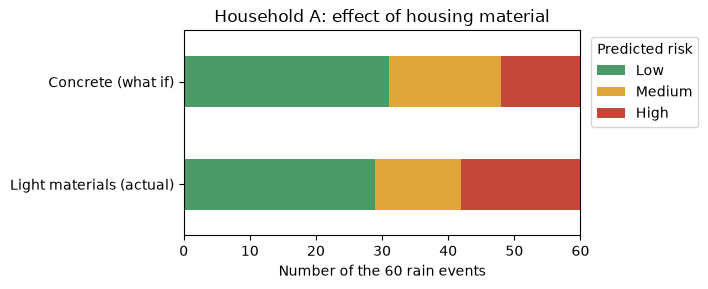

Highest-rain events for Household A:


,EventDate,EventType,Rainfall24hMm,PredictedRisk,P_High
0,2020-02-20,Extreme,226.13,High,1.0
1,2017-09-11,Extreme,200.72,High,1.0
2,2020-11-15,Extreme,181.76,High,1.0
3,2024-10-24,Extreme,159.90,High,1.0
4,2015-12-15,Extreme,158.76,High,1.0


In [45]:
# What if Household A's house were made of concrete? Only HousingMaterial changes.
profile_a = exposed[PROFILE_COLS].to_dict()
what_if = dict(profile_a, HousingMaterial="Concrete")
res_a, res_w = assess_household(profile_a), assess_household(what_if)
compare = pd.DataFrame({"Light materials (actual)": res_a.PredictedRisk.value_counts(),
                        "Concrete (what if)": res_w.PredictedRisk.value_counts()}).reindex(LEVELS).fillna(0).astype(int)
display(compare)

fig, ax = plt.subplots(figsize=(7.2, 3.0))
compare.T.plot.barh(stacked=True, ax=ax, color=["#4c9a6a", "#e0a63a", "#c4473a"])
ax.set_xlabel("Number of the 60 rain events")
ax.set_xlim(0, 60)
ax.set_title("Household A: effect of housing material")
ax.legend(title="Predicted risk", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "demo_what_if.png"), dpi=150)
plt.show()

res_a.to_csv(os.path.join(OUT_DIR, "demo_household_A.csv"), index=False)
assess_household(safe[PROFILE_COLS].to_dict()).to_csv(os.path.join(OUT_DIR, "demo_household_B.csv"), index=False)
print("Highest-rain events for Household A:")
res_a.sort_values("Rainfall24hMm", ascending=False).head(5)

### 7.3 Prediction check against the true labels of a test household
For records that have a label, the demonstration can be checked directly.

In [46]:
check_rows = final_predictions[final_predictions.HouseholdID == exposed.HouseholdID]
print(f"{exposed.HouseholdID}: {check_rows.Correct.sum()} of {len(check_rows)} events predicted correctly")
check_rows[["EventDate", "TrueRiskLevel", "PredictedRiskLevel", "Prob_High", "Correct"]].head(10)

AGAP-SCL-02652: 28 of 30 events predicted correctly


,EventDate,TrueRiskLevel,PredictedRiskLevel,Prob_High,Correct
76500,1991-07-09,Medium,Medium,0.0001,True
76501,1993-12-27,Medium,Medium,0.0004,True
76502,1995-02-02,Low,Low,0.0000,True
76503,1996-02-13,Low,Low,0.0000,True
76504,2003-06-16,Low,Low,0.0000,True
76505,2004-05-12,Low,Low,0.0000,True
76506,2008-06-07,Low,Low,0.0000,True
76507,2009-04-29,High,Medium,0.2982,False
76508,2009-09-03,Low,Low,0.0000,True
76509,2009-10-30,High,High,0.9995,True


### 7.4 Conclusions
1. **The model learns the AGAP risk rule closely.** The final gradient boosting model reached a macro F1 of 0.979
   (95% CI 0.976–0.983) on 1,548 households it had never seen, and 0.980 on average over five household-grouped folds.
   Recall on the High level was 0.969 on the test set and 0.975 on average across the folds.
2. **Gradient boosting is the right choice for this data.** It clearly outperformed Random Forest (macro F1 0.949) and
   Logistic Regression (0.846). The linear model also predicted 250 Low records as High, which gradient boosting never did.
3. **The Week 5 changes helped on every fold.** Adding effective rainfall and the dependents count, and using smaller
   trees (15 leaves, learning rate 0.2), raised macro F1 in all five folds. The lowest fold F1 on High rose from 0.956
   to 0.962, which meets the 0.96 target that the baseline missed. Both changes were chosen on a validation split, not
   on the test set.
4. **The remaining errors are borderline cases.** 98% of the errors have a risk score within 3 points of a cut-off,
   and the model never confuses Low with High.
5. **Weak spots exist.** High-risk households in concrete houses are caught less often (recall 0.943) than those in
   light-material houses (0.979), and a few barangays have too few High records for reliable estimates.
6. **The results describe agreement with a rule, not real flood prediction.** The labels are rule-based and the household
   details are simulated. Before the system is used to plan real evacuations, its predictions should be checked against
   recorded flood events, for example barangay and MDRRMO reports.

The web application currently runs the baseline setting (model agap-noah-v2.8). The improved setting from this notebook
is the recommended next version.

### 7.5 Download all outputs (Colab)

In [47]:
import shutil
archive = shutil.make_archive("AGAP_outputs", "zip", OUT_DIR)
print("Created", archive, "with", len(os.listdir(OUT_DIR)), "files")
if IN_COLAB:
    from google.colab import files
    files.download(archive)

Created C:\Users\Karl Sebastian\AppData\Local\Temp\claude\962946289b316d8c\37154ade-4e2c-400c-84fe-64b7f403f721\scratchpad\rerun\AGAP_outputs.zip with 28 files
